# [두구두구두구] 팀 대항전

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

## 0. 팀 대항전 진행 방법

<div style="background:#FFFFFF;color:#000000;padding:40px;border-radius:12px;border:1px solid #E6E6E6;border-left:4px solid #051C2C">
<div style="font-size:0.9em;color:#656565">AI 데이터 인텔리전스 전문가 과정 · 딥러닝 시계열</div>
<h1 style="color:#000000;margin:10px 0">딥러닝 시계열 복습 팀 대항전</h1>
<div style="font-size:1.05em;color:#656565">글로벌 모델부터 임계비율까지 배운 결정 규칙을 묻는 일곱 문항을 팀으로 풉니다</div>
</div>

문항은 일곱 개입니다. 초급·중급·고급이 두 개씩이고, 마지막 문제 7 은 초심화입니다. 문항마다 상황과 자료를 읽고 보기 다섯 가운데 하나를 고릅니다.

1. 팀원이 각자 보기 하나를 고르고 「내 답」에 고른 까닭을 적습니다. 「내 입장」은 A～E 가운데 하나를, 확신도는 1～5 가운데 하나를 골라 냅니다. 내 답을 내면 팀의 답 분포가 바로 보입니다.
2. 지금까지 낸 팀원이 두 명 이상이고 모두 같은 보기를 골랐으면 「변호인 질문」이 뜹니다. 팀이 질문에 답을 적고, 그 보기를 지킬지 바꿀지 정합니다. 답이 갈려 있으면 질문 없이 팀 답으로 넘어갑니다.
3. 출석한 팀원이 모두 낸 뒤, 내 답을 낸 팀원 한 명이 팀 답으로 고른 보기와 까닭을 두세 문장으로 적어 냅니다. 팀 답은 한 번만 낼 수 있습니다.
4. 이 화면에는 정답과 해설이 열리지 않습니다. 모든 팀이 팀 답을 내면 강사가 정답과 해설을 함께 풉니다.

딥러닝 시계열 이론과 레퍼런스는 풀면서 봐도 됩니다. 시간이 모자라면 문제 2 를 건너뜁니다.

문항의 승차 인원은 서울 지하철 100개 역의 자료입니다. 예측과 점수는 모두 아래 그림의 다섯 주에서 나온 값이고, 그림의 한 행이 예측 원점 하나의 채점 7일입니다. 인력 비용과 인력 1명이 맡는 승차 인원 2,000명은 가정입니다.

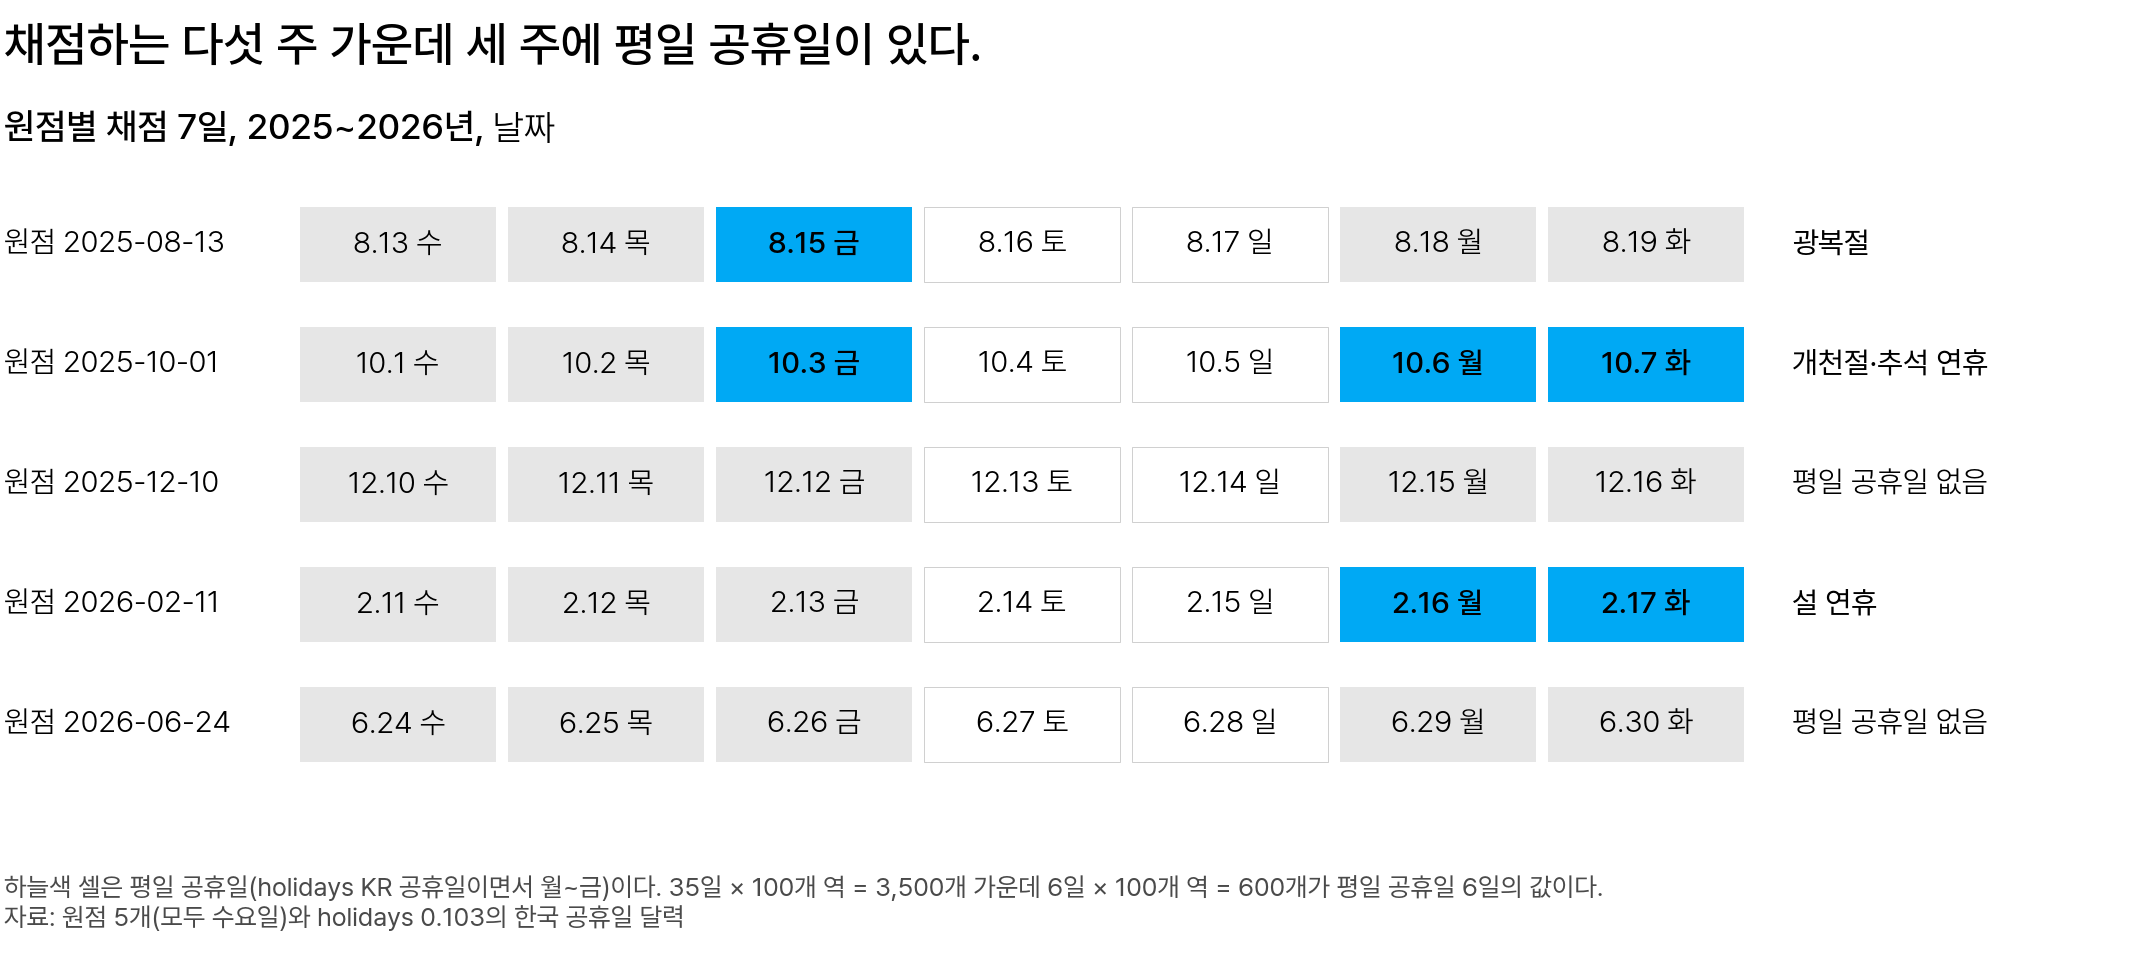

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 채점하는 다섯 주. 한 행이 원점 하나의 채점 7일(수～화)이고, 회색 셀은 평일, 흰 셀은 주말, 하늘색 셀은 평일 공휴일이다. 오른쪽 글자는 그 주의 공휴일 이름이다. 공휴일은 파이썬 라이브러리 holidays 0.103 버전의 한국 공휴일 달력을 따른다</em></p>

공휴일 있는 세 주는 원점 2025-08-13 · 2025-10-01 · 2026-02-11 입니다. 공휴일 없는 두 주는 원점 2025-12-10 · 2026-06-24 입니다.

## 1. 문제 1 · 초급 · 새 비용으로 정하는 인력

임계비율 문항입니다.

**상황**

운영팀 분석가로서 역마다 둘 인력을 Chronos-2 + 공휴일의 예측 표로 정합니다. 지금까지는 모자란 1명·일 60만 원, 남는 1명·일 15만 원으로 인력을 정했습니다. 운영팀이 두 비용을 다시 계산해 보냈습니다. 모자란 인력 1명·일은 35만 원, 남는 인력 1명·일은 15만 원입니다.

인력 1명이 하루 승차 인원 2,000명을 맡는다는 가정은 그대로입니다. 동료들이 새 비용으로 둘 인력을 서로 다르게 정해 왔습니다.

**자료**

2호선 잠실역의 2026-06-24(수)입니다. 예측 원점 2026-06-24 의 예측 표 한 행에서 분위수 다섯 개를 옮겼습니다.

| 분위수 | 0.3 | 0.5 | 0.7 | 0.8 | 0.9 |
|---|---:|---:|---:|---:|---:|
| 승차 인원(명) | 82,297 | 83,169 | 84,318 | 85,230 | 86,779 |
| ÷ 2,000명(명) | 41.15 | 41.58 | 42.16 | 42.61 | 43.39 |

둘째 행은 반올림하기 전의 승차 인원을 나눈 값이라 첫 행의 수로 나누면 0.01명 다를 수 있습니다.

> **[문제] 팀 라운드: 문제 1. 예측 원점의 아침에 이날 잠실역에 둘 인력을 정한다면 몇 명일까요?**
>
> 예측 원점의 아침에 이날 잠실역에 둘 인력을 정한다면 몇 명일까요?
> 
> - **A.** 43.39명입니다. 80% 구간을 배울 때처럼 위 끝 0.9 분위수에 맞춥니다
> - **B.** 41.15명입니다. 0.3 분위수를 2,000명으로 나눕니다
> - **C.** 42.16명입니다. 0.7 분위수를 2,000명으로 나눕니다
> - **D.** 42.61명입니다. 임계비율을 배울 때 정한 0.8 분위수에 맞춥니다
> - **E.** 41.58명입니다. 점 예측으로 쓰는 0.5 분위수에 맞춥니다

## 2. 문제 2 · 초급 · 설 연휴의 보정한 예측값

공변량과 설 연휴 보정 문항입니다.

**상황**

설 연휴가 있는 주(예측 원점 2026-02-11)의 잠실역 인력을 정하는 운영팀 분석가입니다. 설 연휴 평일 이틀은 Chronos-2 + 공휴일의 예측 대신 보정한 예측값을 쓰기로 했습니다. 동료들이 계산해 온 2월 17일(화, 설날)의 보정한 예측값이 서로 다릅니다.

**자료**

2호선 잠실역의 실제 승차 인원입니다. 비는 공변량을 배울 때처럼 소수 셋째 자리로 반올림해 곱합니다.

| 2호선 잠실 | 값 |
|---|---:|
| 2026-02-10(화)의 승차 인원 | 82,306명 |
| 2025-01-28(화, 지난해 설날 전날)의 승차 인원 | 39,165명 |
| 2025-01-28 의 같은 요일 평균 | 79,155명 |
| 2025-01-29(수, 지난해 설날)의 승차 인원 | 33,307명 |
| 2025-01-29 의 같은 요일 평균 | 78,717명 |
| 2026-02-17 의 같은 요일 평균 | 80,702명 |

같은 요일 평균은 그날보다 1주 · 2주 앞과 뒤의 같은 요일 4일로 구합니다. 그 가운데 공휴일이 아닌 날의 승차 인원만 평균합니다. 표의 평균은 1명 단위로 반올림했습니다. 공변량을 배울 때 구한 강남역 지난해 설날의 비는 0.142 였습니다.

보정한 예측값은 1주 전 같은 요일 승차 인원에 지난해 같은 날의 비를 곱한 값입니다. 비는 그날 승차 인원을 그날의 같은 요일 평균으로 나눈 값입니다.

> **[문제] 팀 라운드: 문제 2. 잠실역 2월 17일의 보정한 예측값은 몇 명일까요?**
>
> 잠실역 2월 17일의 보정한 예측값은 몇 명일까요?
> 
> - **A.** 11,460명입니다. 80,702명에 강남역의 비 0.142 를 곱합니다
> - **B.** 34,137명입니다. 80,702명에 비 0.423 을 곱합니다
> - **C.** 40,741명입니다. 82,306명에 비 0.495 를 곱합니다
> - **D.** 39,947명입니다. 80,702명에 비 0.495 를 곱합니다
> - **E.** 34,815명입니다. 82,306명에 비 0.423 을 곱합니다

## 3. 문제 3 · 중급 · 계절 나이브보다 오차가 큰 역

글로벌 모델과 역 단위 MASE 문항입니다.

**상황**

예측 원점 2026-06-24 의 채점 7일이 지난 뒤 운영팀 분석가로서 역별 오차를 정리합니다. 예측은 Chronos-2 + 공휴일의 0.5 분위수입니다. 운영팀은 역마다, 그 역의 같은 주 계절 나이브보다 더 크게 틀린 역만 골라 다시 확인하려 합니다.

**자료**

원점 2026-06-24 의 채점 7일입니다. 이 주 100개 역의 계절 나이브 MASE 는 0.471 입니다.

| 역 | Chronos-2 + 공휴일의 7일 평균 절대 오차 | MASE 분모 $Q_i$ | 같은 역 계절 나이브의 MASE |
|---|---:|---:|---:|
| 2호선 삼성 | 6,171명 | 5,957.7명 | 1.055 |
| 2호선 잠실 | 1,951명 | 6,405.5명 | 0.518 |
| 4호선 명동 | 1,703명 | 2,509.1명 | 1.184 |
| 2호선 역삼 | 979명 | 4,923.1명 | 0.102 |

$Q_i$ 는 원점 전날까지 계절 나이브가 그 역에서 낸 절대 오차의 평균입니다.

시드 범위는 0.077 입니다. 시드는 가중치의 처음 값과 학습 순서를 정하는 난수의 출발값입니다. 글로벌 모델을 배울 때 MLP(MSE 손실)를 시드 0～4 로 다섯 번 학습했습니다. 원점 5개 평균 MASE 는 1.771～1.848 이었습니다.

가장 큰 값에서 가장 작은 값을 뺀 0.077 은 같은 방법을 다시 학습하기만 해도 생기는 차이입니다. 그래서 여러 원점을 평균한 MASE 의 차이가 0.077 보다 작으면 두 방법에 차이가 있다고 보지 않습니다.

> **[문제] 팀 라운드: 문제 3. 운영팀이 다시 확인할 역은 표의 네 역 가운데 어디일까요?**
>
> 운영팀이 다시 확인할 역은 표의 네 역 가운데 어디일까요?
> 
> - **A.** 삼성입니다. 6,171 ÷ 5,957.7 ≈ 1.04 로 MASE 가 1 보다 큽니다
> - **B.** 삼성과 명동입니다. MASE 가 이 주 계절 나이브의 0.471 보다 높습니다
> - **C.** 잠실 · 명동 · 역삼입니다. 계절 나이브와의 차이가 0.077 보다 큽니다
> - **D.** 역삼입니다. MASE 가 979 ÷ 4,923.1 ≈ 0.20 입니다
> - **E.** 없습니다. 네 역 MASE 의 평균 0.55 가 계절 나이브의 평균 0.71 보다 낮습니다

## 4. 문제 4 · 중급 · 전임 담당자의 채점 결과

공변량 문항입니다.

**상황**

전임 담당자가 남긴 채점 결과를 평가표에 옮기는 운영팀 분석가입니다. 전임 담당자는 Chronos-2 에 공휴일 정보를 전달하는 방법 셋을 원점 5개에서 채점해 두었습니다. 메모에는 ③ 이 두 열 모두에서 가장 낮으니 ③ 을 평가표에 적자고 쓰여 있습니다.

**자료**

공변량을 배울 때 계산한 역 단위 MASE 입니다. ① 은 공휴일 있는 세 주에서만 채점했습니다.

| 구성 | 과거 표 `df` 의 열 | 미래 입력 `future_df` 의 열 | 공휴일 있는 세 주 | 공휴일 없는 두 주 |
|---|---|---|---:|---:|
| Chronos-2 제로샷 | 승차 | 없음 | 2.763 | 0.271 |
| ① | 승차 · 공휴일 | 없음 | 2.756 | 채점하지 않음 |
| ② | 승차 · 공휴일 | 공휴일 | 1.022 | 0.322 |
| ③ | 승차 · 공휴일 · 하차 | 공휴일 · 하차 | 0.342 | 0.158 |

시드 범위는 0.077 입니다. 시드는 가중치의 처음 값과 학습 순서를 정하는 난수의 출발값입니다. 글로벌 모델을 배울 때 MLP(MSE 손실)를 시드 0～4 로 다섯 번 학습했습니다. 원점 5개 평균 MASE 는 1.771～1.848 이었습니다.

가장 큰 값에서 가장 작은 값을 뺀 0.077 은 같은 방법을 다시 학습하기만 해도 생기는 차이입니다. 그래서 여러 원점을 평균한 MASE 의 차이가 0.077 보다 작으면 두 방법에 차이가 있다고 보지 않습니다.

> **[문제] 팀 라운드: 문제 4. 평가표에 「제로샷과 차이가 있다」고 적을 수 있는 값을 모두 고르면 무엇일까요?**
>
> 평가표에 「제로샷과 차이가 있다」고 적을 수 있는 값을 모두 고르면 무엇일까요?
> 
> - **A.** ③ 의 두 값입니다. 제로샷과의 차이 2.421 · 0.113 이 모두 0.077 보다 큽니다
> - **B.** ② 의 공휴일 있는 세 주 하나입니다. 2.763 − 1.022 = 1.741 입니다
> - **C.** ② 의 두 값입니다. 누수가 없고, 제로샷과의 차이가 1.741 · 0.051 입니다
> - **D.** ① 과 ② 의 공휴일 있는 세 주입니다. 0.007 · 1.741 만큼 낮아졌습니다
> - **E.** 하나도 없습니다. ② 도 채점 7일의 공휴일 값을 `future_df` 에 포함합니다

## 5. 문제 5 · 고급 · 다른 팀이 보낸 제로샷 점수

사전학습 모델 Chronos-2 제로샷의 채점 문항입니다.

**상황**

운영팀 분석가로서 평가표를 관리합니다. 다른 팀이 Chronos-2 제로샷을 다시 채점한 결과를 보냈습니다. 그 팀의 예측 방법은 아래 첫 표와 같고 예측 원점은 모두 수요일입니다.

그 팀은 평가표의 결론 「공휴일 있는 세 주에는 제로샷과 계절 나이브가 같다」를 고치자고 합니다. 공휴일 있는 세 주에서 제로샷이 2.302 로 계절 나이브 2.767 보다 0.465 낮다는 것이 근거입니다. 이 차이가 시드 범위 0.077 보다 크다는 점도 함께 썼습니다.

**자료**

예측할 날과 입력한 승차 인원의 마지막 날입니다. 그 날을 예측할 때 승차 인원을 어느 날까지 입력했는지 적었습니다.

| 예측할 날 | 수 | 목 | 금 | 토 | 일 | 월 | 화 |
|---|---|---|---|---|---|---|---|
| 마지막 날(다른 팀) | 화 | 수 | 목 | 금 | 토 | 일 | 월 |
| 마지막 날(평가표) | 화 | 화 | 화 | 화 | 화 | 화 | 화 |

역 단위 MASE 입니다. 다른 팀의 값은 그 팀이 보낸 원점별 값의 평균이고 나머지는 평가표의 값입니다.

| 방식 | 공휴일 없는 두 주 | 공휴일 있는 세 주 |
|---|---:|---:|
| 제로샷(다른 팀) | 0.259 | 2.302 |
| 제로샷(평가표) | 0.271 | 2.763 |
| 계절 나이브(평가표) | 0.445 | 2.767 |

다른 팀의 원점별 값 가운데 원점 2025-10-01(개천절 · 추석 연휴)은 3.519 입니다. 같은 주의 계절 나이브는 4.388 입니다.

평가표에는 원점 전날까지의 승차 인원으로 7일을 한 번에 예측한 점수를 적습니다.

시드 범위는 0.077 입니다. 시드는 가중치의 처음 값과 학습 순서를 정하는 난수의 출발값입니다. 글로벌 모델을 배울 때 MLP(MSE 손실)를 시드 0～4 로 다섯 번 학습했습니다. 원점 5개 평균 MASE 는 1.771～1.848 이었습니다.

가장 큰 값에서 가장 작은 값을 뺀 0.077 은 같은 방법을 다시 학습하기만 해도 생기는 차이입니다. 그래서 여러 원점을 평균한 MASE 의 차이가 0.077 보다 작으면 두 방법에 차이가 있다고 보지 않습니다.

> **[문제] 팀 라운드: 문제 5. 이 요청에 평가표로 답하면 어느 것이 맞을까요?**
>
> 이 요청에 평가표로 답하면 어느 것이 맞을까요?
> 
> - **A.** 고치지 않습니다. 평가표에서는 제로샷 2.763 과 계절 나이브 2.767 이 0.004 차이입니다
> - **B.** 고칩니다. 2.302 는 계절 나이브 2.767 보다 0.465 낮고, 시드 범위 0.077 보다 큰 차이입니다
> - **C.** 고칩니다. 두 제로샷은 공휴일 없는 두 주에서 0.012 차이라, 0.077 보다 작습니다
> - **D.** 계절 나이브도 다른 팀과 같은 방법으로 다시 채점해, 그 값을 2.302 와 비교해 정합니다
> - **E.** 원점 2025-10-01 의 주만 고칩니다. 그 주는 3.519 로, 계절 나이브 4.388 보다 0.869 낮습니다

## 6. 문제 6 · 고급 · 개천절과 추석 연휴 주의 계획표

평일 공휴일 당일의 인력 문항입니다.

**상황**

개천절과 추석 연휴가 있는 주(예측 원점 2025-10-01)의 인력 계획표를 운영팀 분석가로서 검토합니다. 동료 분석가가 100개 역의 인력을 Chronos-2 + 공휴일의 예측 표로 정했습니다. 두 비용은 처음 가정대로 60만 원과 15만 원이고, 인력 1명은 하루 승차 인원 2,000명을 맡습니다.

이 주의 평일 공휴일은 사흘입니다. 동료는 나머지 나흘을 0.8 분위수 ÷ 2,000명으로 정했고, 평일 공휴일 사흘은 아래처럼 정했습니다.

**자료**

| 날 | 동료가 정한 인력 | 동료가 적은 근거 |
|---|---|---|
| 10월 3일(금, 개천절) | 0.9 분위수 ÷ 2,000명, 계획표에 표시 | 평일 공휴일 당일 600점의 포함률이 46.5% 였다 |
| 10월 6일(월, 추석) | 보정한 예측값 ÷ 2,000명, 계획표에 표시 | 공휴일 열의 값 1 에는 어느 공휴일인지가 없다 |
| 10월 7일(화, 추석 다음날) | 0.8 분위수 ÷ 2,000명, 계획표에 표시 | 임계비율이 60 ÷ (60 + 15) = 0.8 이다 |

보정한 예측값은 1주 전 같은 요일 승차 인원에 지난해 같은 날의 비를 곱한 값입니다.

공변량을 배울 때 Chronos-2 + 공휴일 예측의 100개 역 합을 실제와 비교했습니다. 광복절 · 개천절 · 추석 연휴 이틀은 실제의 0.84～1.18배였고, 설 연휴 평일 이틀은 1.40 · 1.50배였습니다. 0.8 분위수 인력이 모자라지 않은 역은 광복절 73개, 개천절 22개, 추석 97개, 추석 다음날 90개였습니다. 목표는 100개 역 가운데 80개입니다.

> **[문제] 팀 라운드: 문제 6. 이 사흘의 행 가운데 고쳐야 할 행을 모두 고르면 무엇일까요?**
>
> 이 사흘의 행 가운데 고쳐야 할 행을 모두 고르면 무엇일까요?
> 
> - **A.** 세 행 모두입니다. 10월 3일과 6일, 7일 행을 모두 고칩니다
> - **B.** 10월 6일과 7일 두 행입니다. 10월 3일 행은 그대로 둡니다
> - **C.** 10월 3일과 6일 두 행입니다. 10월 7일 행은 그대로 둡니다
> - **D.** 10월 3일과 7일 두 행입니다. 10월 6일 행은 그대로 둡니다
> - **E.** 고칠 행이 없습니다. 세 행을 모두 그대로 둡니다

## 7. 문제 7 · 초심화 · 시드 범위를 조금 넘는 차이

글로벌 모델과 시드 범위 문항입니다.

**상황**

공휴일 없는 주에 쓸 모델을 정하는 운영팀 분석가입니다. 동료의 보고서 초안은 공휴일 없는 주에 Chronos-2 제로샷을 쓰자고 제안합니다. 제로샷의 MASE 가 MLP(MAE 손실)보다 0.088 낮고, 0.088 이 시드 범위 0.077 보다 크다는 것이 근거입니다.

**자료**

글로벌 모델을 배울 때 계산한 공휴일 없는 두 주의 평균 MASE 입니다.

| 모델 | 평가표의 값 | 시드 0～4 로 다시 학습한 다섯 값 |
|---|---:|---|
| Chronos-2 제로샷 | 0.271 | 학습하지 않으므로 늘 0.271 |
| MLP(MAE 손실) | 0.359 | 0.356～0.372 |

원점 5개 평균 MASE 는 제로샷 1.766, MLP(MAE 손실) 1.774 입니다.

시드 범위는 0.077 입니다. 시드는 가중치의 처음 값과 학습 순서를 정하는 난수의 출발값입니다. 글로벌 모델을 배울 때 MLP(MSE 손실)를 시드 0～4 로 다섯 번 학습했습니다. 원점 5개 평균 MASE 는 1.771～1.848 이었습니다.

같은 다섯 번의 학습에서 MLP(MSE 손실)의 공휴일 없는 두 주 평균 MASE 는 0.571～0.739 였습니다.

가장 큰 값에서 가장 작은 값을 뺀 0.077 은 같은 방법을 다시 학습하기만 해도 생기는 차이입니다. 그래서 여러 원점을 평균한 MASE 의 차이가 0.077 보다 작으면 두 방법에 차이가 있다고 보지 않습니다.

> **[문제] 팀 라운드: 문제 7. 초안의 결론과 근거를 어떻게 고치면 될까요?**
>
> 초안의 결론과 근거를 어떻게 고치면 될까요?
> 
> - **A.** 그대로 둡니다. 0.088 은 시드 범위 0.077 보다 크므로 제로샷이 낫다는 근거가 됩니다
> - **B.** 「차이가 없다」로 고칩니다. 두 주 평균은 0.571～0.739 로 0.168 까지 달라져 0.088 은 이보다 작습니다
> - **C.** 「MLP(MAE 손실)도 나을 수 있다」로 고칩니다. 시드에 따라 0.168 까지 달라지면 순서가 반대가 될 수 있습니다
> - **D.** 결론은 두고 근거를 바꿉니다. MLP(MAE 손실)의 다섯 값이 모두 제로샷 0.271 보다 높습니다
> - **E.** 「차이가 없다」로 고칩니다. 원점 5개 평균의 차이 1.774 − 1.766 = 0.008 이 0.077 보다 작습니다